# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Olan Lastiant Afri
- NIM   : 241011400346
- Kelas : ~~Reg B /~~ Reg C *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [43]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 46   # isi dengan 2 digit terakhir NIM Anda

In [44]:
# Salin fungsi train_test_split dari materi di sini

# train_test_split:
# this function splits the dataset into training and testing sets based on the specified test size and random state.
# the method takes in the features (X), target variable (y), test size, and random state as inputs and returns the training and testing sets for both features and target variable.
# example usage:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7)

def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
40


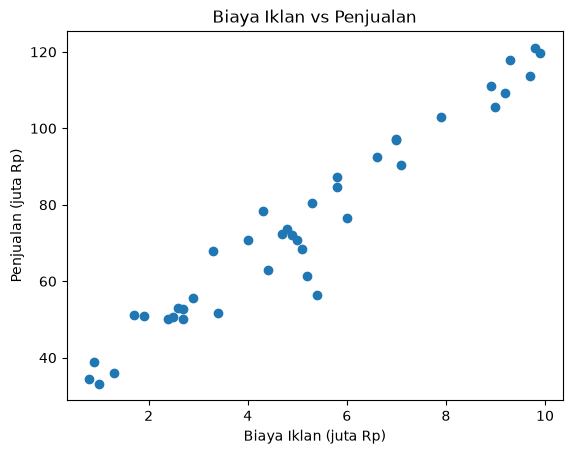

In [46]:
# Jawaban A1

df = pd.read_csv("Ads_Data.csv")
print(df.head()); print(len(df))
X = df[["BiayaIklan"]].values
y = df["Penjualan"].values
plt.scatter(X, y); plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)"); plt.ylabel("Penjualan (juta Rp)"); plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [47]:
# Jawaban A2

X_train, X_test, y_train, y_test = train_test_split(X, y, 0.2, RANDOM_STATE)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(32, 1) (8, 1) (32,) (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [48]:
# Jawaban A3
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

regressor = LinearRegression()
regressor.fit(X_train, y_train)
print("Intercept (b):", regressor.intercept_)
print("Koefisien (m):", regressor.coefficients_)

Intercept (b): 28.465590163830736
Koefisien (m): [9.02216236]


**Jawaban A3 (interpretasi):**

Persamaan regresinya ŷ = 28.4656 + 9.0222X. Nilai m = 9.02 artinya kalau biaya iklan naik Rp.1 juta, penjualan naik sekitar Rp.9,02 juta.

Intercept 28.47 artinya kalau tidak ada biaya iklan, penjualan diperkirakan sekitar Rp.28,47 juta

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [49]:
# Jawaban A4

def mae(y_true, y_pred):  return np.mean(np.abs(y_true - y_pred))
def mse(y_true, y_pred):  return np.mean((y_true - y_pred) ** 2)
def rmse(y_true, y_pred): return np.sqrt(mse(y_true, y_pred))
def r2_score(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)

hasil = {}
for nama, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    p = regressor.predict(Xs)
    hasil[nama] = [mae(ys, p), mse(ys, p), rmse(ys, p), r2_score(ys, p)]
print(pd.DataFrame(hasil, index=["MAE", "MSE", "RMSE", "R2"]).T)

            MAE        MSE      RMSE        R2
Train  4.983002  41.860989  6.470007  0.923153
Test   2.790405  13.198206  3.632933  0.986257


**Jawaban A4 (analisis):**

RMSE data test 3.63 artinya rata-rata prediksi meleset sekitar Rp.3,6 juta, cukup kecil dibanding penjualan yang berkisar puluhan sampai ratusan juta. R² test 0.986 berarti hampir semua variasi penjualan bisa dijelaskan oleh biaya iklan.

Menurut saya modelnya sudah baik dan tidak overfitting karena hasil di data test tidak lebih jelek dari data train (R² train 0.923). Data test hanya 8 titik, jadi angka yang bagus ini bisa jadi kebetulan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Normal equation -> intercept: 28.465590163830736  koefisien: [9.02216236]
lr=0.001 -> intercept: 17.758806771658982, koefisien: [10.70352114]
lr=0.02 -> intercept: 28.46558979236023, koefisien: [9.02216242]


C:\Users\olan.lastiant\AppData\Local\Temp\ipykernel_23216\1448571562.py:29: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b @ beta) ** 2)
C:\Users\olan.lastiant\AppData\Local\Temp\ipykernel_23216\1448571562.py:26: RuntimeWarning: overflow encountered in matmul
  gradient = X_b.T @ (y_hat - y) / len(y)
C:\Users\olan.lastiant\AppData\Local\Temp\ipykernel_23216\1448571562.py:27: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient


lr=0.1 -> intercept: nan, koefisien: [nan]


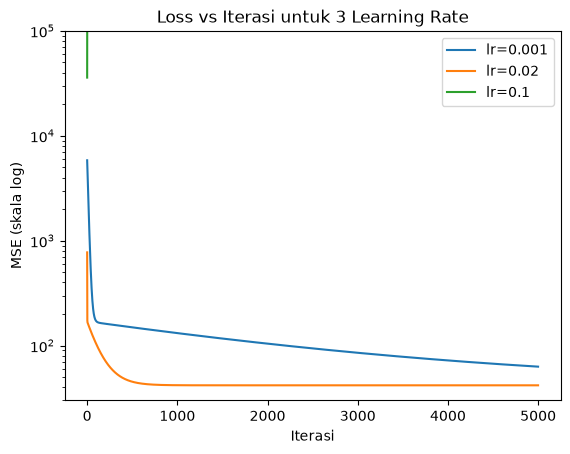

In [52]:
# Jawaban A5


class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    # Training
    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    # Testing
    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_


# Latih dengan 3 learning rate dan bandingkan dengan normal equation
print("Normal equation -> intercept:", regressor.intercept_, " koefisien:", regressor.coefficients_)
for lr in [0.001, 0.02, 0.1]:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model.fit(X_train, y_train)
    print(f"lr={lr} -> intercept: {model.intercept_}, koefisien: {model.coefficients_}")
    plt.plot(model.loss_history_, label=f"lr={lr}")

# Grafik loss vs iterasi
plt.yscale("log")
plt.ylim(30, 1e5)
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.title("Loss vs Iterasi untuk 3 Learning Rate")
plt.legend()
plt.show()

**Jawaban A5 (analisis):**

Dengan learning rate 0.001 modelnya terlalu lambat. Setelah 5000 iterasi intercept dan koefisiennya masih 17.76 dan 10.70, belum sampai ke hasil normal equation (28.47 dan 9.02). Learning rate 0.02 pas, hasilnya sama dengan normal equation dan loss-nya turun cepat lalu datar.

Learning rate 0.1 divergen karena langkahnya terlalu besar, jadi koefisien terus melompati titik minimum dan error makin besar sampai hasilnya nan. Warning overflow muncul karena angkanya sudah terlalu besar untuk ditampung tipe float, itu tanda gradient descent-nya gagal konvergen.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

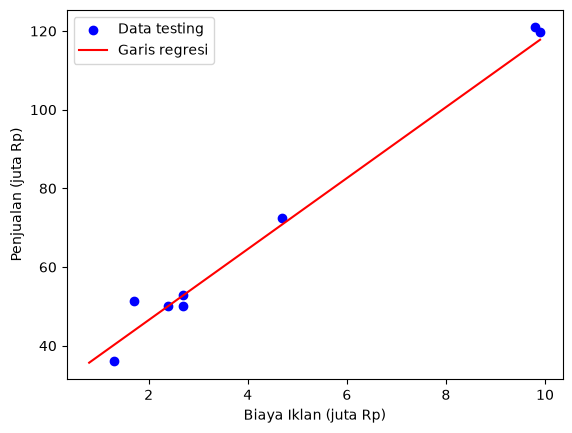

4.5 [69.0653208]
7 [91.62072671]
12 [136.73153853]


In [53]:
# Jawaban A6

x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.scatter(X_test, y_test, c="blue", label="Data testing")
plt.plot(x_line, regressor.predict(x_line), c="r", label="Garis regresi")
plt.xlabel("Biaya Iklan (juta Rp)"); plt.ylabel("Penjualan (juta Rp)"); plt.legend(); plt.show()

for biaya in [4.5, 7, 12]:
    print(biaya, regressor.predict([[biaya]]))

**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta masing-masing 69.07 juta, 91.62 juta, dan 136.73 juta. Data kita hanya sampai biaya iklan sekitar 9.9 juta, jadi 12 juta itu di luar jangkauan data (ekstrapolasi).

Saya kurang percaya hasilnya karena belum tentu hubungannya tetap lurus di angka segitu, bisa saja kenaikan penjualannya melambat. Jadi 136.73 juta sebaiknya dianggap perkiraan kasar saja.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1
Spam
0    35
1    25
Name: count, dtype: int64


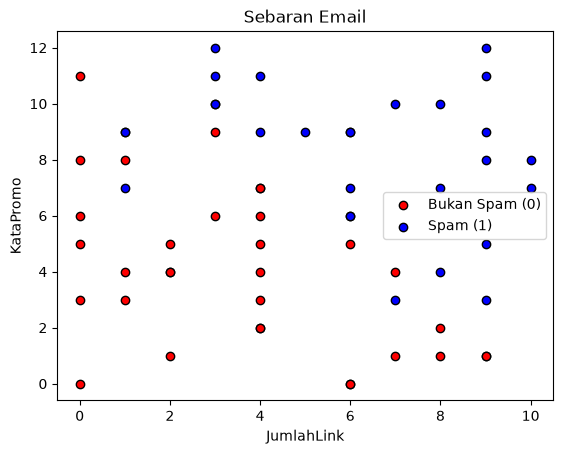

In [55]:
# Jawaban B1

df_email = pd.read_csv("Email_Data.csv")
print(df_email.head())
print(df_email["Spam"].value_counts())

X = df_email[["JumlahLink", "KataPromo"]].values
y = df_email["Spam"].values

plt.scatter(X[y == 0, 0], X[y == 0, 1], c="red", edgecolors="k", label="Bukan Spam (0)")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="blue", edgecolors="k", label="Spam (1)")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo"); plt.title("Sebaran Email"); plt.legend(); plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

(45, 2) (15, 2)
Intercept: -10.408025829692313
Koefisien: [0.86696126 0.89438803]


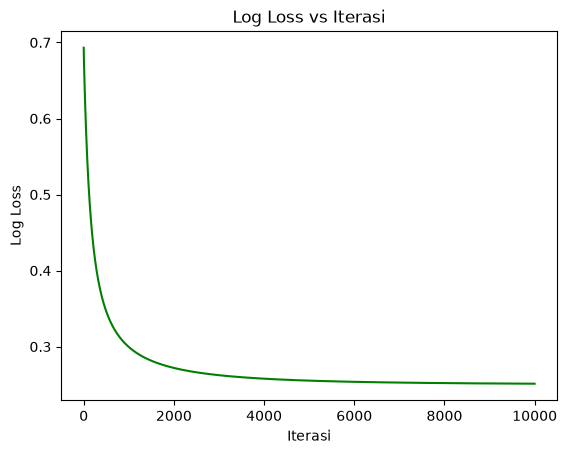

In [56]:
# Jawaban B2


class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)   # (45, 2) (15, 2)

classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(X_train, y_train)
print("Intercept:", classifier.intercept_)
print("Koefisien:", classifier.coefficients_)

plt.plot(classifier.loss_history_, c="g")
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.show()

**Jawaban B2 (analisis):**

Persamaannya P(Spam) = σ(−10.408 + 0.867·JumlahLink + 0.894·KataPromo). Kedua koefisien positif, jadi makin banyak link dan kata promo, makin besar kemungkinan email itu spam.

Log loss turun dari 0.693 di awal ke sekitar 0.25 di akhir dan kurvanya sudah hampir datar, jadi loss sudah turun dan stabil.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [57]:
# Jawaban B3


def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp],
                     [fn, tp]])

def precision_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

y_pred = classifier.predict(X_test)
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))

Accuracy : 0.8
Confusion Matrix:
 [[6 1]
 [2 6]]
Precision: 0.8571428571428571
Recall   : 0.75
F1-score : 0.7999999999999999


**Jawaban B3 (analisis):**

FP artinya email biasa yang salah dianggap spam (ada 1), sedangkan FN artinya spam yang lolos ke inbox (ada 2). Menurut saya FP lebih merugikan karena email penting bisa masuk folder spam dan tidak terbaca.

Kalau FN pengguna cuma perlu menghapus email spam itu sendiri.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = -(-10.408 + 0.867 * x1) / 0.894


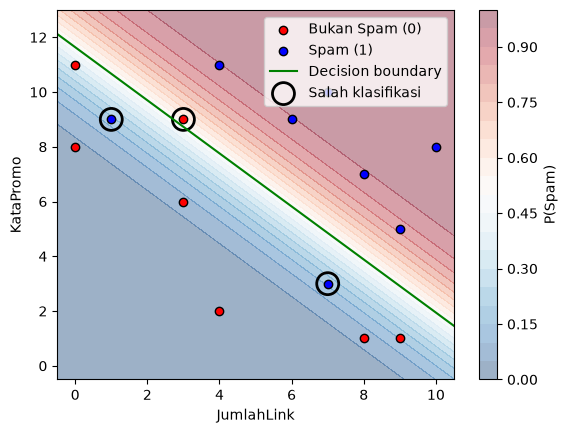

Data salah klasifikasi:
 [[3 9]
 [1 9]
 [7 3]]
Label asli: [0 1 1]
P(Spam): [0.56  0.184 0.16 ]


In [58]:
# Jawaban B4


b = classifier.intercept_
m1, m2 = classifier.coefficients_
print(f"Decision boundary: x2 = -({b:.3f} + {m1:.3f} * x1) / {m2:.3f}")   # x2 = 11.637 - 0.969 * x1

x1, x2 = np.meshgrid(np.linspace(-0.5, 10.5, 200), np.linspace(-0.5, 13, 200))
proba_grid = classifier.predict_proba(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)
x1_line = np.linspace(-0.5, 10.5, 100)
x2_line = -(b + m1 * x1_line) / m2

plt.contourf(x1, x2, proba_grid, levels=20, cmap="RdBu_r", alpha=0.4)
plt.colorbar(label="P(Spam)")
plt.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="red", edgecolors="k", label="Bukan Spam (0)")
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="blue", edgecolors="k", label="Spam (1)")
plt.plot(x1_line, x2_line, c="g", label="Decision boundary")

salah = classifier.predict(X_test) != y_test
plt.scatter(X_test[salah, 0], X_test[salah, 1], s=250, facecolors="none", edgecolors="black", linewidths=2, label="Salah klasifikasi")

plt.xlim(-0.5, 10.5); plt.ylim(-0.5, 13)
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(loc="upper right"); plt.show()

print("Data salah klasifikasi:\n", X_test[salah])
print("Label asli:", y_test[salah])
print("P(Spam):", classifier.predict_proba(X_test)[salah].round(3))

**Jawaban B4 (analisis):**

Ada 3 data test yang salah diprediksi. Satu bukan spam tapi diprediksi spam (3 link, 9 kata promo), dan dua lainnya spam tapi diprediksi bukan spam (1 link 9 kata promo, dan 7 link 3 kata promo).

Ketiganya dekat dengan garis batas atau ada di area yang bercampur antara dua kelas, jadi susah dipisahkan oleh satu garis lurus.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [59]:
# Jawaban B5


proba = classifier.predict_proba(X_test)
rows = []
for t in [0.3, 0.5, 0.7]:
    pred_t = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    rows.append([t, tn, fp, fn, tp, precision_score(y_test, pred_t), recall_score(y_test, pred_t)])

print(pd.DataFrame(rows, columns=["Threshold", "TN", "FP", "FN", "TP", "Precision", "Recall"]))

   Threshold  TN  FP  FN  TP  Precision  Recall
0        0.3   5   2   2   6   0.750000    0.75
1        0.5   6   1   2   6   0.857143    0.75
2        0.7   7   0   2   6   1.000000    0.75


**Jawaban B5 (analisis):**

Kalau threshold dinaikkan, model jadi lebih jarang menyebut email sebagai spam, sehingga FP turun dan precision naik, tapi recall bisa turun. Kalau threshold diturunkan, hasilnya sebaliknya.

Di data ini recall tetap 0.75 untuk semua threshold, sedangkan precision naik dari 0.75 (threshold 0.3) ke 1.0 (threshold 0.7). Karena menurut jawaban B3 FP lebih merugikan, saya pilih threshold 0.7 karena FP-nya jadi 0.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [60]:
# Jawaban B6


email_baru = np.array([[1, 2], [5, 6], [9, 10], [2, 11]])
proba_baru = classifier.predict_proba(email_baru)
kelas_baru = classifier.predict(email_baru, threshold=0.7)

hasil = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": email_baru[:, 0],
    "KataPromo": email_baru[:, 1],
    "P(Spam)": proba_baru.round(4),
    "Prediksi": ["Spam" if k == 1 else "Bukan Spam" for k in kelas_baru],
})
print(hasil)

  Email  JumlahLink  KataPromo  P(Spam)    Prediksi
0    E1           1          2   0.0004  Bukan Spam
1    E2           5          6   0.3303  Bukan Spam
2    E3           9         10   0.9982        Spam
3    E4           2         11   0.7621        Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression dipakai untuk klasifikasi karena hasil akhirnya kelas 0 atau 1, bukan angka bebas. Sigmoid mengubah hasil hitungan linear jadi probabilitas 0 sampai 1, lalu dipotong pakai threshold untuk menentukan kelasnya.

**Jawaban C2:**
Normal equation menghitung koefisien langsung sekali jalan pakai rumus matriks, sedangkan gradient descent memperbaikinya sedikit demi sedikit lewat banyak iterasi. Gradient descent lebih cocok kalau datanya atau fiturnya sangat banyak, karena invers matriks jadi berat.

**Jawaban C3:**
Model sudah "melihat" data training, jadi skor di sana belum tentu menunjukkan performa sebenarnya. Data testing dipakai untuk mengukur performa di data baru. Overfitting itu saat model terlalu menghafal data training sehingga bagus di training tapi jelek di testing.

**Jawaban C4:**
Linear Regression outputnya angka, jadi errornya diukur dengan selisih kuadrat (MSE). Logistic Regression outputnya probabilitas, dan log loss memberi hukuman besar kalau model yakin tapi salah.

**Jawaban C5:**
Karena random_state dari NIM membuat pembagian data train dan test berbeda. Data training yang beda menghasilkan koefisien dan metrik yang beda juga.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [61]:
# Jawaban Bonus

**Jawaban Bonus (analisis):**